# Extra Figure 7 — the 5-qubit QFT: GEOPE against L-BFGS GRAPE across its hyperparameters

The problem of the paper's Fig. 4(c): the 5-qubit QFT on the Rydberg array of Fig. 2(c), a unit square of atoms with a fifth at its centre, driven by a Rabi drive $\Omega_i\sigma^x_i$ and a detuning $\Delta_i\sigma^z_i$ on every atom over a fixed van der Waals drift $\sum_{i<j}J_{ij}\sigma^z_i\sigma^z_j$ with $J_{ij}\propto r_{ij}^{-6}$ (edges at $1/8$ of the centre coupling, diagonals at $1/64$), at $L=120$ segments. There the Newton-family GRAPE rules found no solution within 300 steps and took hours per run, because every step pays a dense $(P,P)$ Hessian and its eigendecomposition at $P=1200$.

L-BFGS is the GRAPE rule that does not pay that: no Hessian, $O(mP)$ per step for a memory of $m$ curvature pairs. So it is the one that could keep up with GEOPE on this problem, and the question here is whether any setting of its hyperparameters does. GEOPE runs as in Fig. 3 (Armijo on geodesic distance, $t_{\max}=1$) and has nothing to tune. L-BFGS is swept over the three knobs that shape its step — the memory $m$, the trial-step cap $t_{\max}$ and the strong-Wolfe curvature constant $c_2$ — one at a time around the setting Figure 3 uses, and additionally with its line search swapped from strong Wolfe to backtracking Armijo. Both initial spreads of Figure 3 are run: $\pi/100$, where L-BFGS fails on the Toffoli, and $\pi$, the setting of Fig. 5.

In [1]:
from common import *

## The problem and the grid

The same ten seeds for every setting: `random_pulse` draws the initial pulse from the seed and the spread alone, so every curve at one spread starts from the same ten points, and a difference between curves is a difference between optimisers.

The iteration budgets differ on purpose. GEOPE keeps Figure 4(c)'s 300 steps. An L-BFGS step is several times cheaper, so it gets a larger budget, chosen so that its wall-clock allowance is at least GEOPE's; a comparison that cut L-BFGS off at 300 iterations would be a comparison of iteration counts, which is not the quantity that matters when the steps cost different amounts.

In [2]:
N_RUNS = 10
L_STEPS = 120
SPREADS = (0.01, 1.0)
SPREAD_LABELS = {0.01: r"\pi/100", 1.0: r"\pi"}

#: Figure 4(c)'s budget for GEOPE on this problem; L-BFGS's steps are cheaper, so it
#: gets more of them, enough that its wall-clock allowance exceeds GEOPE's.
GEOPE_MAX_STEPS = 300
LBFGS_MAX_STEPS = 1000
GEOPE_LINE_SEARCH = Armijo()

#: Figure 3's L-BFGS, the point every single-knob sweep below passes through.
LBFGS_BASE = LBFGS(memory=100)

#: The knobs, each swept with the other two held at `LBFGS_BASE`.
LBFGS_KNOBS = {
    "memory": dict(
        values=(5, 10, 25, 50, 100, 200),
        axis=r"Curvature pairs $m$",
    ),
    "max_step": dict(
        values=(0.1, 1.0, 10.0),
        axis=r"Trial-step cap $t_{\max}$",
    ),
    "c2": dict(
        values=(0.1, 0.5, 0.9),
        axis=r"Wolfe curvature constant $c_2$",
    ),
}

#: The line search itself: the strong-Wolfe default against backtracking Armijo,
#: which tests sufficient decrease alone and so can accept an arbitrarily short step.
LBFGS_LINE_SEARCHES = {
    "Wolfe": LBFGS_BASE,
    "Armijo": dataclasses.replace(LBFGS_BASE, wolfe=False),
}


def lbfgs_variant(knob, value):
    """`LBFGS_BASE` with one field changed, cast to that field's type."""
    kind = type(getattr(LBFGS_BASE, knob))
    return dataclasses.replace(LBFGS_BASE, **{knob: kind(value)})


def lbfgs_slug(config):
    """A readable name for one setting: the memory, then whatever else differs from the base."""
    parts = [f"m{config.memory}"]
    if config.max_step != LBFGS_BASE.max_step:
        parts.append(f"tmax{value_slug(config.max_step)}")
    if config.c2 != LBFGS_BASE.c2:
        parts.append(f"c2{value_slug(config.c2)}")
    if not config.wolfe:
        parts.append("armijo")
    return "LBFGS_" + "_".join(parts)


#: Every distinct setting, ``{slug: config}``. The base appears in all three knob
#: sweeps and the line-search pair, and is run once.
LBFGS_CONFIGS = {}
for knob, spec in LBFGS_KNOBS.items():
    for value in spec["values"]:
        config = lbfgs_variant(knob, value)
        LBFGS_CONFIGS[lbfgs_slug(config)] = config
for config in LBFGS_LINE_SEARCHES.values():
    LBFGS_CONFIGS.setdefault(lbfgs_slug(config), config)

QFT5_COUPLINGS = rydberg_couplings(rydberg_positions(5))
print(f"{len(LBFGS_CONFIGS)} L-BFGS settings + GEOPE, x {len(SPREADS)} spreads x {N_RUNS} seeds")
for slug, config in LBFGS_CONFIGS.items():
    print(f"  {slug:24s} {config!r}")

11 L-BFGS settings + GEOPE, x 2 spreads x 10 seeds
  LBFGS_m5                 LBFGS(memory=5, c1=0.0001, beta=0.5, t_min=1e-10, max_step=1.0, increase=1.5, wolfe=True, c2=0.9)
  LBFGS_m10                LBFGS(memory=10, c1=0.0001, beta=0.5, t_min=1e-10, max_step=1.0, increase=1.5, wolfe=True, c2=0.9)
  LBFGS_m25                LBFGS(memory=25, c1=0.0001, beta=0.5, t_min=1e-10, max_step=1.0, increase=1.5, wolfe=True, c2=0.9)
  LBFGS_m50                LBFGS(memory=50, c1=0.0001, beta=0.5, t_min=1e-10, max_step=1.0, increase=1.5, wolfe=True, c2=0.9)
  LBFGS_m100               LBFGS(memory=100, c1=0.0001, beta=0.5, t_min=1e-10, max_step=1.0, increase=1.5, wolfe=True, c2=0.9)
  LBFGS_m200               LBFGS(memory=200, c1=0.0001, beta=0.5, t_min=1e-10, max_step=1.0, increase=1.5, wolfe=True, c2=0.9)
  LBFGS_m100_tmax0p1       LBFGS(memory=100, c1=0.0001, beta=0.5, t_min=1e-10, max_step=0.1, increase=1.5, wolfe=True, c2=0.9)
  LBFGS_m100_tmax10        LBFGS(memory=100, c1=0.0001, beta=0.5,

## The cache

One block per setting and spread, keyed by the sha1 of the whole config dict — the model's couplings included, since they are data rather than presentation — and extended rather than replaced, so raising `N_RUNS` computes only the new seeds and an interrupted sweep resumes where it stopped. The per-seed timing, the model and the slugs come from `common.py`; what is local here is the block's config.

In [3]:
def fig9_config(spread, series, config, max_steps):
    """Everything that changes this block's numbers.

    ``series`` is ``"GEOPE"`` or an L-BFGS slug; it is in the *tag* as well as in
    the config, so a block is identifiable on disk without opening its sidecar.
    The iteration budget is in the key because the two methods' budgets differ.
    """
    cfg = {
        "tag": f"fig9_QFT5_L{L_STEPS}_{spread_slug(spread)}_{series}",
        "kind": "fig9-qft5-geope-vs-lbfgs",
        "gate": "QFT5",
        "n_qubits": 5,
        "steps": L_STEPS,
        "couplings": {str(k): round(v, 12) for k, v in QFT5_COUPLINGS.items()},
        "method": "GEOPE" if series == "GEOPE" else "LBFGS",
        "series": series,
        "config": repr(config),
        "spread": float(spread),
        "max_steps": int(max_steps),
        "precision": PRECISION,
    }
    if series == "GEOPE":
        cfg["geope_max_step"] = GEOPE_MAX_STEP
    return cfg


def fig9_runs():
    """``(series, config, max_steps)`` for every curve at one spread, GEOPE first."""
    return [("GEOPE", GEOPE_LINE_SEARCH, GEOPE_MAX_STEPS)] + [
        (slug, config, LBFGS_MAX_STEPS) for slug, config in LBFGS_CONFIGS.items()
    ]


def fig9_sweep(n_runs=None, force=False, verbose=True):
    """Every block, keyed ``(spread, series)``; each value is ``(fidelities, seconds)``."""
    n_runs = N_RUNS if n_runs is None else n_runs
    blocks = {}
    for spread in SPREADS:
        for series, config, max_steps in fig9_runs():

            def build(series=series, config=config, spread=spread):
                params = make_parameters_rydberg(5, L_STEPS, "QFT5", spread=spread)
                optimiser = (
                    Geope(params, history=History())
                    if series == "GEOPE"
                    else Grape(params, precision=PRECISION, history=History())
                )
                return params, optimiser, config

            blocks[(spread, series)] = run_block(
                fig9_config(spread, series, config, max_steps),
                build,
                n_runs,
                spread=spread,
                force=force,
                verbose=verbose,
                max_steps=max_steps,
            )
    return blocks


fig9_blocks = fig9_sweep()

  fig9_QFT5_L120_spread0p01pi_GEOPE        10/10 converged  median  60.22s   cached (10 stored)


  fig9_QFT5_L120_spread0p01pi_LBFGS_m5      0/10 converged  median  88.87s   cached (10 stored)


  fig9_QFT5_L120_spread0p01pi_LBFGS_m10     0/10 converged  median 100.52s   cached (10 stored)


  fig9_QFT5_L120_spread0p01pi_LBFGS_m25     0/10 converged  median 102.30s   cached (10 stored)


  fig9_QFT5_L120_spread0p01pi_LBFGS_m50     0/10 converged  median  80.01s   cached (10 stored)


  fig9_QFT5_L120_spread0p01pi_LBFGS_m100    0/10 converged  median  78.51s   cached (10 stored)


... (14 outputs left out)

  fig9_QFT5_L120_spread1pi_LBFGS_m100_tmax10 10/10 converged  median   8.13s   cached (10 stored)


  fig9_QFT5_L120_spread1pi_LBFGS_m100_c20p1 10/10 converged  median   5.12s   cached (10 stored)


  fig9_QFT5_L120_spread1pi_LBFGS_m100_c20p5 10/10 converged  median   8.08s   cached (10 stored)


  fig9_QFT5_L120_spread1pi_LBFGS_m100_armijo 10/10 converged  median   4.33s   cached (10 stored)


## Summary

Per setting and spread: the fraction of seeds reaching $1-F<10^{-9}$ within the budget, and the median iterations, wall clock and final infidelity over all ten seeds. The medians are censored at the budget, as in the hyperparameter search: a setting that does not land reports the budget's iterations and the time they took, not a smaller number over the seeds that happened to converge.

In [4]:
def summarise(blocks):
    """One tidy row per ``(spread, series)``."""
    rows = []
    for (spread, series), (fids, secs) in blocks.items():
        final = np.array([1.0 - f[-1] for f in fids])
        rows.append(
            {
                "spread": float(spread),
                "series": series,
                "converged": float(np.mean(final < 1.0 - PRECISION)),
                "steps": float(np.median([f.size - 1 for f in fids])),
                "seconds": float(np.median([t[-1] for t in secs])),
                "infidelity": float(np.median(final)),
            }
        )
    return pd.DataFrame(rows).set_index(["spread", "series"])


summary = summarise(fig9_blocks)
order = [series for series, _config, _budget in fig9_runs()]
width = max(len(s) for s in order) + 2
print(" " * width + "".join(f"{'spread ' + f'{s:g}':>36s}" for s in SPREADS))
print(" " * width + "".join(f"{'conv':>6s}{'steps':>8s}{'s':>9s}{'1-F':>10s}   " for _ in SPREADS))
for series in order:
    line = f"{series:{width}s}"
    for spread in SPREADS:
        row = summary.loc[(spread, series)]
        line += (
            f"{row['converged'] * N_RUNS:4.0f}/{N_RUNS:<2d}"
            f"{row['steps']:7.0f} {row['seconds']:8.1f} {row['infidelity']:10.1e}   "
        )
    print(line)

                                             spread 0.01                            spread 1
                      conv   steps        s       1-F     conv   steps        s       1-F   
GEOPE                 10/10    146     60.2    2.6e-10     10/10    136     47.8    1.2e-10   
LBFGS_m5               0/10   1000     88.9    2.1e-05     10/10     63      5.3    9.0e-10   
LBFGS_m10              0/10   1000    100.5    1.3e-05     10/10     60      5.4    8.4e-10   
LBFGS_m25              0/10   1000    102.3    5.1e-06     10/10     60      4.9    8.5e-10   
LBFGS_m50              0/10   1000     80.0    2.8e-06     10/10     59      5.3    8.2e-10   
LBFGS_m100             0/10   1000     78.5    1.2e-06     10/10     59      5.1    8.1e-10   
LBFGS_m200             0/10   1000     79.6    5.2e-07     10/10     59      5.0    8.1e-10   
LBFGS_m100_tmax0p1     0/10   1000     76.0    5.5e-06     10/10    116      9.9    8.9e-10   
LBFGS_m100_tmax10      9/10     86     12.2    8.5e-10

## Figures — each knob's sweep against GEOPE

Figure 3's layout, once per knob: infidelity against iteration (left) and against each run's own wall clock (right), one row per initial spread, medians over faint individual runs. GEOPE in blue; L-BFGS at each value of the knob in a single hue, light for the smallest value and dark for the largest, with the other two knobs at the base setting. The iteration axis is logarithmic because the two budgets span a decade and the settings separate within the first hundred steps; step 0 is dropped as it is on the wall-clock axis.

figures/extra_fig7_qft5_lbfgs_memory_L120.pdf


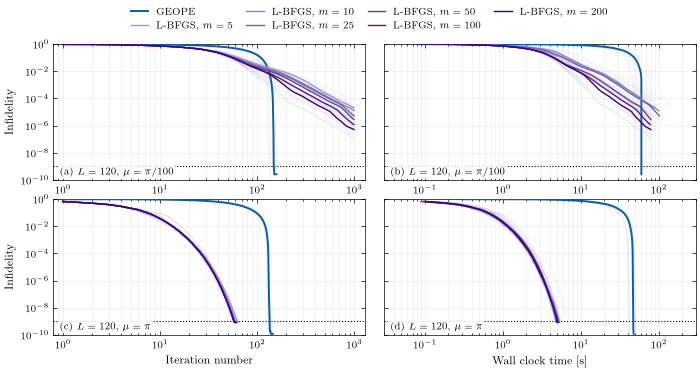

figures/extra_fig7_qft5_lbfgs_max_step_L120.pdf


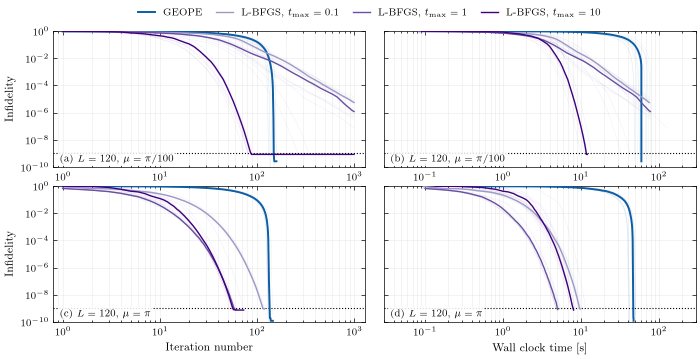

figures/extra_fig7_qft5_lbfgs_c2_L120.pdf


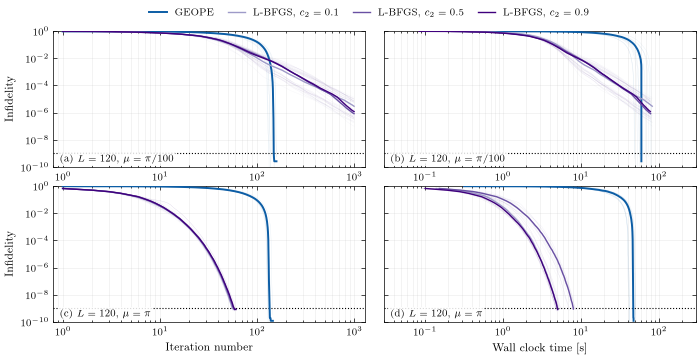

In [5]:
KNOB_SYMBOLS = {"memory": "m", "max_step": r"t_{\max}", "c2": "c_2"}


def knob_series(knob):
    """``{value: slug}`` for one knob's sweep, in the grid's order."""
    return {
        value: lbfgs_slug(lbfgs_variant(knob, value))
        for value in LBFGS_KNOBS[knob]["values"]
    }


def knob_styles(knob):
    """Line styles for GEOPE and one knob's sweep, keyed by series.

    GEOPE keeps its usual colour and weight; the sweep shares one hue, light for
    the smallest value and dark for the largest.
    """
    values = LBFGS_KNOBS[knob]["values"]
    ramp = plt.cm.Purples(np.linspace(0.5, 1.0, len(values)))
    styles = {"GEOPE": method_style("GEOPE")}
    for value, slug, colour in zip(values, knob_series(knob).values(), ramp):
        styles[slug] = dict(
            lw=1.0, ls="-", color=colour, zorder=3,
            label=rf"L-BFGS, ${KNOB_SYMBOLS[knob]}={value:g}$",
        )
    return styles


def draw_series_iterations(ax, blocks, styles):
    """`draw_iterations` for series rather than methods, on a log axis from step 1."""
    for series, style in styles.items():
        for y in infidelities(blocks[series][0]):
            ax.loglog(np.arange(1, y.size), y[1:], color=style["color"], **FAINT)
    for series, style in styles.items():
        y = median_over_runs(infidelities(blocks[series][0]))
        ax.loglog(np.arange(1, y.size), y[1:], **style)
    ax.set_xlabel("Iteration number")


def draw_series_walltime(ax, blocks, styles):
    """`draw_walltime` for series rather than methods; step 0 sits at t = 0 and is dropped."""
    for series, style in styles.items():
        fids, secs = blocks[series]
        for y, t in zip(infidelities(fids), secs):
            ax.semilogy(t[1:], y[1:], color=style["color"], **FAINT)
    for series, style in styles.items():
        fids, secs = blocks[series]
        y = median_over_runs(infidelities(fids))
        t = median_over_runs(secs)
        ax.semilogy(t[1:], y[1:], **style)
    ax.set_xscale("log")
    ax.set_xlabel("Wall clock time [s]")


def trajectory_figure(knob):
    """One Figure-1-style panel grid: GEOPE against the sweep of ``knob``."""
    styles = knob_styles(knob)
    fig, axes = plt.subplots(
        len(SPREADS), 2, figsize=(TWO_COLUMN, 3.4), sharey=True, squeeze=False,
        gridspec_kw=dict(wspace=0.06, hspace=0.14),
    )
    for row, spread in enumerate(SPREADS):
        ax_iter, ax_time = axes[row]
        blocks = {series: fig9_blocks[(spread, series)] for series in styles}
        draw_series_iterations(ax_iter, blocks, styles)
        draw_series_walltime(ax_time, blocks, styles)
        finish(ax_iter, "")
        finish(ax_time, "")
        ax_iter.set_xlim(0.8, 1300)
        ax_time.set_xlim(3e-2, 3e2)
        for ax, letter in zip((ax_iter, ax_time), "abcd"[2 * row:]):
            ax.text(
                0.02, 0.04, rf"({letter}) $L={L_STEPS}$, $\mu={SPREAD_LABELS[spread]}$",
                transform=ax.transAxes, fontsize=ANNOTATION_SIZE, zorder=5,
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.2),
            )
        ax_iter.set_ylabel("Infidelity")
        if row < len(SPREADS) - 1:
            ax_iter.set_xlabel("")
            ax_time.set_xlabel("")

    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(
        handles, labels, loc="lower center", frameon=False,
        ncol=len(styles) if len(styles) <= 5 else 4,
        bbox_to_anchor=(0.53, 1.0), handlelength=1.8, columnspacing=1.4,
    )
    fig.subplots_adjust(left=0.085, right=0.99, top=0.985, bottom=0.13)
    print(save_figure(fig, f"extra_fig7_qft5_lbfgs_{knob}_L{L_STEPS}"))
    plt.show()


for knob in LBFGS_KNOBS:
    trajectory_figure(knob)

## Figure — every knob

Three columns, one per knob, read as the hyperparameter search: the median wall clock to the target on top, the median iterations in the middle and the fraction of seeds converged at the bottom, one colour per initial spread. The dashed lines are GEOPE at the same spread, which has no knob and so is flat across every panel. The grey dotted vertical line marks the base setting the other two knobs are held at. The medians are censored at the budget, drawn as the dotted ceiling in the iterations row: a point sitting on it has not converged, and the bottom row says so.

The Armijo line-search variant has no axis to sit on; it is in the summary table above.

figures/extra_fig7_qft5_lbfgs_knobs_L120.pdf


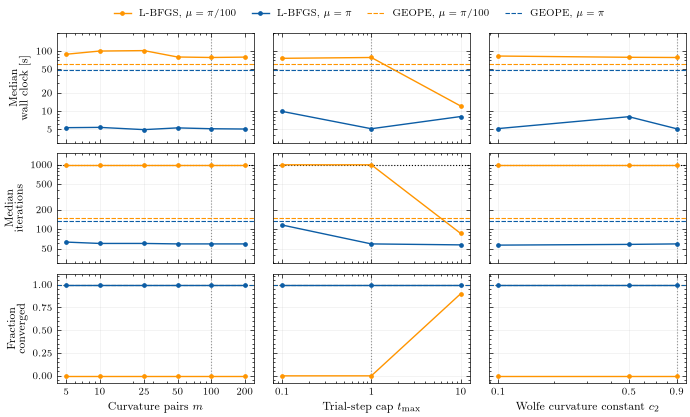

In [6]:
SPREAD_COLOURS = dict(zip(SPREADS, (SCIENCEPLOT_COLOURS[2], SCIENCEPLOT_COLOURS[0])))
#: Explicit ticks on the two log rows; the minor labels clutter a one-decade range.
WALL_CLOCK_TICKS = (5, 10, 20, 50, 100)
ITERATION_TICKS = (50, 100, 200, 500, 1000)
knobs = list(LBFGS_KNOBS)
fig, axes = plt.subplots(
    3, len(knobs), figsize=(TWO_COLUMN, 4.0), sharey="row",
    gridspec_kw=dict(wspace=0.10, hspace=0.10),
)

for column, knob in enumerate(knobs):
    spec = LBFGS_KNOBS[knob]
    ax_sec, ax_it, ax_frac = (axes[row, column] for row in range(3))
    for spread in SPREADS:
        colour = SPREAD_COLOURS[spread]
        rows = pd.DataFrame(
            [
                {"value": value, **summary.loc[(spread, lbfgs_slug(lbfgs_variant(knob, value)))]}
                for value in spec["values"]
            ]
        )
        style = dict(color=colour, marker="o", ms=2.4, lw=1.0, zorder=3)
        ax_sec.plot(rows["value"], rows["seconds"], **style)
        ax_it.plot(rows["value"], rows["steps"], **style)
        ax_frac.plot(rows["value"], rows["converged"], **style)
        reference = summary.loc[(spread, "GEOPE")]
        for ax, key in ((ax_sec, "seconds"), (ax_it, "steps"), (ax_frac, "converged")):
            ax.axhline(reference[key], color=colour, ls=(0, (4, 1.4)), lw=0.8, zorder=2)

    base = getattr(LBFGS_BASE, knob)
    for ax in (ax_sec, ax_it, ax_frac):
        ax.set_xscale("log")
        ax.grid(alpha=0.25, which="major", lw=0.4)
        ax.axvline(base, color="0.55", ls=":", lw=0.8, zorder=1)
        ax.set_xticks(spec["values"])
        ax.set_xticklabels([f"{v:g}" for v in spec["values"]])
        ax.xaxis.set_minor_formatter(NullFormatter())
    ax_it.axhline(LBFGS_MAX_STEPS, color="black", ls=":", lw=0.8, zorder=2)
    for ax, ticks, limits in (
        (ax_sec, WALL_CLOCK_TICKS, (3, 200)),
        (ax_it, ITERATION_TICKS, (30, 1500)),
    ):
        ax.set_yscale("log")
        ax.set_ylim(*limits)
        ax.set_yticks(ticks)
        ax.set_yticklabels([f"{t:g}" for t in ticks])
        ax.yaxis.set_minor_formatter(NullFormatter())
        ax.tick_params(axis="x", which="both", labelbottom=False)
    ax_frac.set_ylim(-0.08, 1.12)
    ax_frac.set_xlabel(spec["axis"])

axes[0, 0].set_ylabel("Median\nwall clock [s]")
axes[1, 0].set_ylabel("Median\niterations")
axes[2, 0].set_ylabel("Fraction\nconverged")
handles = [
    Line2D([], [], color=SPREAD_COLOURS[s], marker="o", ms=2.4, lw=1.0,
           label=rf"L-BFGS, $\mu={SPREAD_LABELS[s]}$")
    for s in SPREADS
] + [
    Line2D([], [], color=SPREAD_COLOURS[s], ls=(0, (4, 1.4)), lw=0.8,
           label=rf"GEOPE, $\mu={SPREAD_LABELS[s]}$")
    for s in SPREADS
]
fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False,
           bbox_to_anchor=(0.53, 1.0), handlelength=1.8, columnspacing=1.6)
fig.subplots_adjust(left=0.105, right=0.99, top=0.985, bottom=0.11,
                    wspace=0.10, hspace=0.10)
print(save_figure(fig, f"extra_fig7_qft5_lbfgs_knobs_L{L_STEPS}"))
plt.show()